# Final model and stress tests

In this notebook I train the final model (a Random Forest on the 40 most important features), I save it and I test it with two experiments:
1. **Tone masks**: I generated the texts with 4 style instructions, one to imitate a human author (Hemingway) and the others to write in an academic way, in a casual way and like a Gen Z teenager.
2. **Imitation between models**: one model tries to write like another one. Since it was an optional request of the project, each LLM imitates only one other model, chosen among the others, but all four of them act as imitator.

In [1]:
import os
os.environ['OTEL_SDK_DISABLED'] = 'true'
import sys
sys.path.insert(0, '.')
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix

from src.data import extract_stylometric_features
from src.analysis import prepare_training_test_sets, get_feature_importance, salva_classificatore

## 1. Data

In [2]:
feat = pd.read_csv('corpus_training_features.csv')     # 800 testi di training
test_feat = pd.read_csv('test_set_features.csv')       # 160 testi con prompt nuovi
print(feat.shape, test_feat.shape)

X_train, X_test, scaler, colonne = prepare_training_test_sets(feat, test_feat)
y_train = feat.modello.values
y_test = test_feat.modello.values

(800, 200) (160, 200)


## 2. Random Forest: all the features against the best 40

In [3]:
rf_tutte = RandomForestClassifier(n_estimators=100, random_state=42)
rf_tutte.fit(X_train, y_train)
acc_tutte = accuracy_score(y_test, rf_tutte.predict(X_test))
print('tutte le feature (' + str(len(colonne)) + '):', round(acc_tutte, 4))

tutte le feature (163): 0.9313


In [4]:
# le 40 feature piu' importanti secondo la foresta appena allenata
top40 = get_feature_importance(rf_tutte, colonne, top_n=40)['feature'].tolist()
print(top40[:10])

['L_PUNCT_DASH', 'ST_TYPE_TOKEN_RATIO_LEMMAS', 'L_CONT_T', 'ST_REPETITIONS_WORDS', 'L_PUNCT', 'L_FUNC_T', 'L_PUNCT_COL', 'POS_CONJ', 'SY_SIMPLE_SENT', 'L_PUNCT_COM']


In [5]:
# nuovo scaler e nuova foresta solo su queste 40 colonne
scaler40 = StandardScaler().fit(feat[top40].fillna(0))
X_train40 = scaler40.transform(feat[top40].fillna(0))
X_test40 = scaler40.transform(test_feat[top40].fillna(0))

rf40 = RandomForestClassifier(n_estimators=100, random_state=42)

rf40.fit(X_train40, y_train)
acc40 = accuracy_score(y_test, rf40.predict(X_test40))
acc40

0.9

Using only the best 40 features (out of 163), the accuracy on the test set goes from 93.1% to 90.0%: only about 3% is lost.
This means that the stylistic fingerprint is concentrated in few features, and for this reason I use the smaller model for the next tests and for saving.

In [6]:
# salvo il modello (nomi nuovi, non sovrascrivo quelli vecchi in models/)
salva_classificatore(rf40, scaler40, top40, filename_prefix='rf_top40')

MODELLO SALVATO CON SUCCESSO
Modello: models/rf_top40_model.pkl
Scaler:  models/rf_top40_scaler.pkl
Colonne: models/rf_top40_cols.pkl


('models/rf_top40_model.pkl',
 'models/rf_top40_scaler.pkl',
 'models/rf_top40_cols.pkl')

## 3. Tone masks

In [7]:
# testi generati con un'istruzione di stile davanti al prompt (80 per maschera)
masked = pd.read_csv('masked_test_set_features.csv').dropna(subset=top40)
print(masked.shape)
masked['pred'] = rf40.predict(scaler40.transform(masked[top40]))
masked['giusto'] = (masked.pred == masked.modello)

acc_maschere = masked.groupby('mask').giusto.mean().sort_values()
print(acc_maschere.round(3))
print('totale:', round(masked.giusto.mean(), 3))

(320, 201)
mask
hemingway    0.588
gen_z        0.700
academic     0.712
casual       0.812
Name: giusto, dtype: float64
totale: 0.703


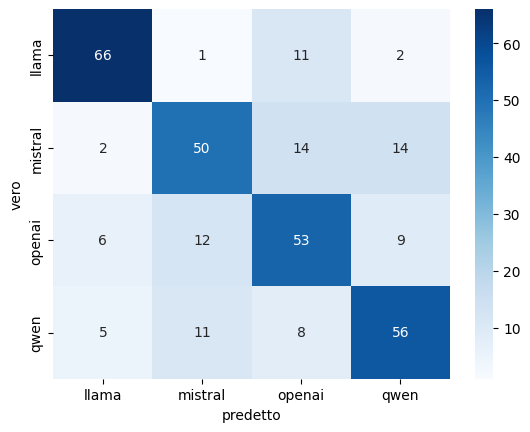

In [8]:
# chi viene scambiato per chi sotto le maschere
mat = confusion_matrix(masked.modello, masked.pred, labels=rf40.classes_)
sns.heatmap(mat, annot=True, fmt='d', cmap='Blues', xticklabels=rf40.classes_, yticklabels=rf40.classes_)
plt.xlabel('predetto')
plt.ylabel('vero')
plt.show()

With the masks the accuracy goes down from 90% to about 70%, but it stays well above chance (25%): the fingerprint gets weaker without disappearing. The mask that hides the model the most is Hemingway (58.8%), that is the imitation of a human author, while the casual one (81.2%) changes it less.
A limit: the prompts are the ones of the training set and the system prompt is generic, so I don't know how much of the drop depends on the mask and how much on the change of system prompt.

## 4. Imitation between models

In [9]:
# un modello (imitatore) riceve 2 testi tipici di un altro (bersaglio) e scrive nel suo stile
cross = pd.read_csv('cross_model_test_set_full.csv')
print(cross.imitation_pair.value_counts())

imitation_pair
llama->mistral     32
mistral->openai    32
qwen->llama        32
openai->qwen       32
Name: count, dtype: int64


In [10]:
# feature dei testi imitati (le estraggo una volta sola e le salvo)
if os.path.exists('cross_model_test_set_full_features.csv'):
    cross_feat = pd.read_csv('cross_model_test_set_full_features.csv')
else:
    tmp = cross.copy()
    tmp['modello'] = tmp['imitator']          # la funzione vuole una colonna 'modello'
    cross_feat = extract_stylometric_features(tmp)
    for col in ['imitation_pair', 'imitator', 'target']:
        cross_feat[col] = cross[col].values
    cross_feat.to_csv('cross_model_test_set_full_features.csv', index=False)
cross_feat.shape

(128, 203)

In [11]:
cross_feat.shape


(128, 203)

In [12]:
cross_feat = cross_feat.dropna(subset=top40).copy()
cross_feat['pred'] = rf40.predict(scaler40.transform(cross_feat[top40]))

righe = []
for coppia, g in cross_feat.groupby('imitation_pair'):
    target, imitatore = g.target.iloc[0], g.imitator.iloc[0]
    righe.append({'coppia': coppia, 'testi': len(g),
                  'ingannato (LLM target)': (g.pred == target).mean() * 100,
                  'smascherato (LLM imitatore)': (g.pred == imitatore).mean() * 100})
tab = pd.DataFrame(righe).set_index('coppia')
tab['Altro LLM'] = 100 - tab['ingannato (LLM target)'] - tab['smascherato (LLM imitatore)']
tab.round(1)

,testi,ingannato (LLM target),smascherato (LLM imitatore),Altro LLM
coppia,,,,
llama->mistral,32,21.9,65.6,12.5
mistral->openai,32,21.9,68.8,9.4
openai->qwen,32,53.1,37.5,9.4
qwen->llama,32,3.1,78.1,18.8


The imitation works mostly with OpenAI imitating Qwen (53% of the texts are taken for Qwen); in the other pairs the classifier unmasks the imitator in most of the cases (from 65% to 78%).
Warning: these are few texts (32 per pair) and, rereading the script, the prompts used are only 2 per genre, repeated 4 times: the percentages are therefore only indicative.

### What changes in the features when GPT-OSS imitates Qwen

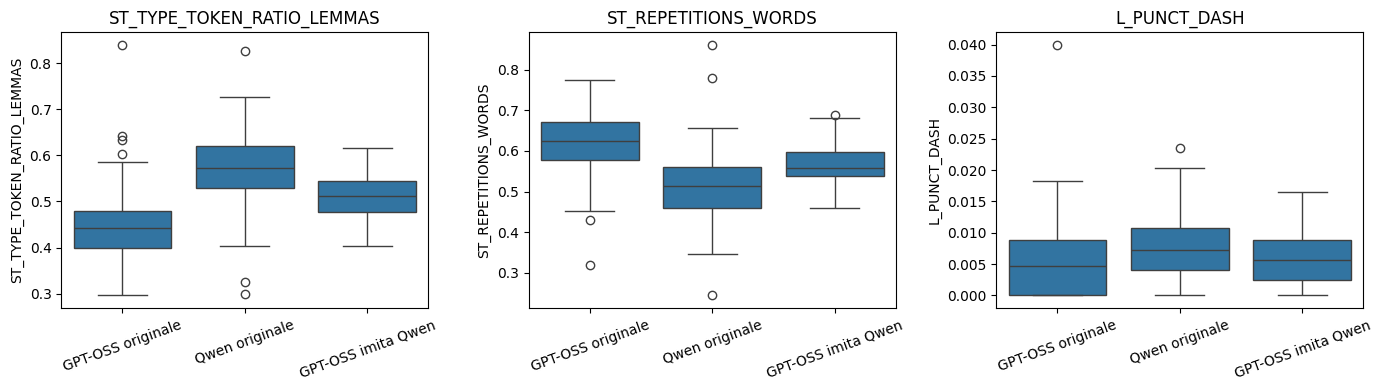

In [13]:
# confronto tra i testi originali dei due modelli (training) e le imitazioni di GPT-OSS verso Qwen
originali = feat[feat.modello.isin(['openai', 'qwen'])].copy()
originali['gruppo'] = originali.modello.map({'openai': 'GPT-OSS originale', 'qwen': 'Qwen originale'})
imitati = cross_feat[cross_feat.imitation_pair == 'openai->qwen'].copy()
imitati['gruppo'] = 'GPT-OSS imita Qwen'

tutti = pd.concat([originali, imitati])
ordine = ['GPT-OSS originale', 'Qwen originale', 'GPT-OSS imita Qwen']

fig, assi = plt.subplots(1, 3, figsize=(14, 4))
for ax, f in zip(assi, ['ST_TYPE_TOKEN_RATIO_LEMMAS', 'ST_REPETITIONS_WORDS', 'L_PUNCT_DASH']):
    sns.boxplot(data=tutti, x='gruppo', y=f, order=ordine, ax=ax)
    ax.set_title(f)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

In the box plot the line is the median and the box contains the central 50% of the texts. The imitations of GPT-OSS towards Qwen are in the middle between the two models: they move towards Qwen but do not reach it.
So the classifier can be fooled even when the style doesn't really match the one of Qwen.

## Conclusions

With the tone masks the accuracy goes down (about 70%) but it stays well above chance, and the imitation between models works only in part (well only for OpenAI imitating Qwen): the stylistic fingerprint is fairly robust and hard to copy.
The limits are the few texts per condition, a single classifier as judge and the lack of a control condition without the mask.